# **House Price Prediction Project**

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [10]:
df = pd.read_csv("dataset.csv")

In [11]:
#remove missing values from target
df = df.dropna(subset=["price"])
df = df[df["price"] > 0].copy()

In [12]:
if "date" in df.columns:
    dates = pd.to_datetime(df["date"], errors="coerce")
    df["sale_year"] = dates.dt.year
    df["sale_month"] = dates.dt.month
    df = df.drop(columns=["date"])


In [13]:
#remove features that might lead to data leakage and affect model performance
df = df.drop(
    columns=["price_per_sqft", "street"],
    errors="ignore"
)

In [14]:
X = df.drop(columns=["price"])
y = df["price"]

In [15]:
constant_columns = [
    col for col in X.columns if X[col].nunique(dropna=False) <= 1
]
X = X.drop(columns=constant_columns)

In [16]:
# Identify numeric and categorical features
categorical_cols = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

In [17]:
for col in categorical_cols:
    X[col] = X[col].astype("string")

print("\nRows after cleaning:", len(X))
print("Numeric features:", numerical_cols)
print("Categorical features:", categorical_cols)


Rows after cleaning: 4551
Numeric features: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'sale_month']
Categorical features: ['city', 'statezip']


In [18]:
#preprocessing

#fill in missing values for categorical features with most frequent:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

#fill in missing values for numerical features with median:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [20]:
#apply transformations using column transformer
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

In [21]:
#split data with train-test split:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [22]:
models = {
    "Linear Regression": (
        LinearRegression(),
        {}
    ),

    "Decision Tree": (
        DecisionTreeRegressor(random_state=42),
        {
            "regressor__max_depth": [5, 10, 15, 20, None],
            "regressor__min_samples_split": [2, 5, 10, 20],
            "regressor__min_samples_leaf": [1, 2, 4, 8]
        }
    ),

    "Random Forest": (
        RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ),
        {
            "regressor__n_estimators": [100, 200, 300],
            "regressor__max_depth": [10, 20, 30, None],
            "regressor__min_samples_split": [2, 5, 10],
            "regressor__min_samples_leaf": [1, 2, 4],
            "regressor__max_features": [1.0, "sqrt", 0.8]
        }
    ),

    "SVR": (
        SVR(),
        {
            "regressor__kernel": ["rbf"],
            "regressor__C": [1, 10, 100, 1000],
            "regressor__epsilon": [0.1, 0.5, 1.0],
            "regressor__gamma": ["scale", 0.01, 0.1]
        }
    ),

    "XGBoost": (
        XGBRegressor(
            objective="reg:squarederror",
            random_state=42,
            n_jobs=1,
            tree_method="hist"
        ),
        {
            "regressor__n_estimators": [200, 400, 600],
            "regressor__max_depth": [3, 4, 6, 8],
            "regressor__learning_rate": [0.03, 0.05, 0.1],
            "regressor__subsample": [0.8, 1.0],
            "regressor__colsample_bytree": [0.8, 1.0],
            "regressor__min_child_weight": [1, 3, 5]
        }
    )
}

In [64]:

results = []
trained_models = {}

for name, (regressor, param_grid) in models.items():

    print("\n" + "=" * 60)
    print("Training:", name)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    if param_grid:
        # Tune hyperparameters using training data only
        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=param_grid,
            n_iter=8,
            scoring="r2",
            cv=3,
            random_state=42,
            n_jobs=-1,
            verbose=1,
            refit=True
        )

        search.fit(X_train, y_train)

        # Get the best fitted model
        best_model = search.best_estimator_
        cv_r2 = search.best_score_
        best_params = search.best_params_

        print("Best parameters:", best_params)

    else:
        # Linear Regression: evaluate with cross-validation
        cv_scores = cross_val_score(
            pipeline,
            X_train,
            y_train,
            scoring="r2",
            cv=3,
            n_jobs=-1
        )

        cv_r2 = cv_scores.mean()

        # Fit the model on the complete training set
        best_model = pipeline.fit(X_train, y_train)
        best_params = "Default"

    trained_models[name] = best_model


Training: Linear Regression

Training: Decision Tree
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'regressor__min_samples_split': 20, 'regressor__min_samples_leaf': 8, 'regressor__max_depth': 10}

Training: Random Forest
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'regressor__n_estimators': 200, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 'sqrt', 'regressor__max_depth': 30}

Training: SVR
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'regressor__kernel': 'rbf', 'regressor__gamma': 'scale', 'regressor__epsilon': 0.5, 'regressor__C': 1000}

Training: XGBoost
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'regressor__subsample': 0.8, 'regressor__n_estimators': 200, 'regressor__min_child_weight': 5, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.03, 'regressor__colsample_bytree': 0.8}


In [29]:
train_predictions = best_model.predict(X_train)
test_predictions = best_model.predict(X_test)

In [30]:
# Evaluation metrics
train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, test_predictions)
mae = mean_absolute_error(y_test, test_predictions)
mse = mean_squared_error(y_test, test_predictions)
rmse = np.sqrt(mse)

print(f"Cross-validation R²: {cv_r2:.4f}")
print(f"Training R²:         {train_r2:.4f}")
print(f"Test R²:             {test_r2:.4f}")
print(f"MAE:                 ${mae:,.2f}")
print(f"RMSE:                ${rmse:,.2f}")

results.append({
    "Model": name,
    "CV R²": cv_r2,
    "Training R²": train_r2,
    "Test R²": test_r2,
    "MAE": mae,
    "MSE": mse,
    "RMSE": rmse,
    "Best Parameters": best_params
})

trained_models[name] = best_model

Cross-validation R²: 0.3305
Training R²:         0.5387
Test R²:             0.6787
MAE:                 $129,885.91
RMSE:                $218,616.01


In [40]:
#model comparison
results_df = pd.DataFrame(results) #convert results to a df

In [32]:
# Rank by cross-validation R², not test R².
# based solely on its performance on the test set.
results_df = results_df.sort_values(
    by="CV R²",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

print(
    results_df[
        ["Model", "CV R²", "Training R²",
         "Test R²", "MAE", "RMSE"]
    ].to_string(
        index=False,
        formatters={
            "CV R²": "{:.4f}".format,
            "Training R²": "{:.4f}".format,
            "Test R²": "{:.4f}".format,
            "MAE": "${:,.2f}".format,
            "RMSE": "${:,.2f}".format
        }
    )
)



FINAL MODEL COMPARISON
  Model  CV R² Training R² Test R²         MAE        RMSE
XGBoost 0.3305      0.5387  0.6787 $129,885.91 $218,616.01


In [33]:
# Select the leading model by cross-validation score
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("\nBest model by cross-validation:", best_name)
print("Its test R²:", round(
    results_df.iloc[0]["Test R²"], 4
))


Best model by cross-validation: XGBoost
Its test R²: 0.6787


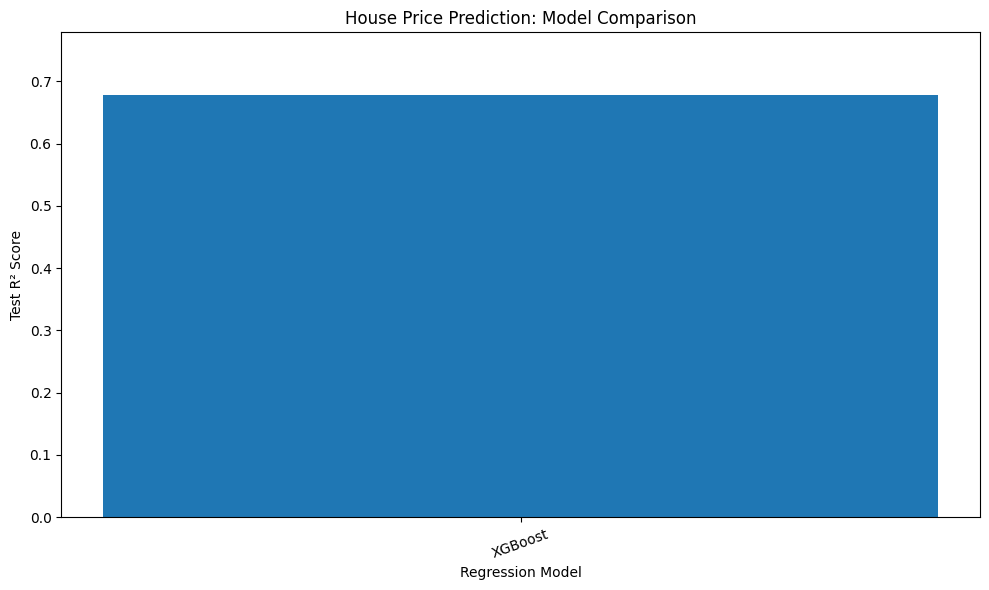

In [34]:
#visualize model comparison

plt.figure(figsize=(10, 6))
plt.bar(
    results_df["Model"],
    results_df["Test R²"]
)
plt.ylabel("Test R² Score")
plt.xlabel("Regression Model")
plt.title("House Price Prediction: Model Comparison")
plt.ylim(
    min(0, results_df["Test R²"].min() - 0.05),
    min(1.0, results_df["Test R²"].max() + 0.1)
)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

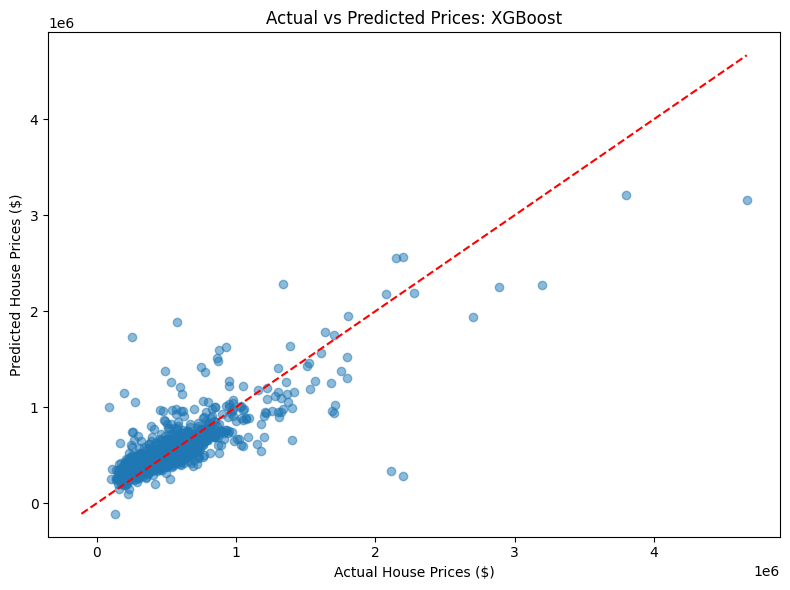

In [35]:
# Compare actual prices with predictions from the leading model
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual House Prices ($)")
plt.ylabel("Predicted House Prices ($)")
plt.title(f"Actual vs Predicted Prices: {best_name}")
plt.tight_layout()
plt.show()


Here are the predictions of a house with the following features:

In [39]:
new_house = {
    "bedrooms": 3,
    "bathrooms": 2.5,
    "sqft_living": 1800,
    "sqft_lot": 5000,
    "floors": 2,
    "waterfront": 0,
    "view": 0,
    "condition": 3,
    "sqft_above": 1500,
    "sqft_basement": 300,
    "yr_built": 1995,
    "yr_renovated": 0,
    "city": "Seattle",
    "statezip": "WA 98103",
    "sale_year": 2014,
    "sale_month": 6
}

In [41]:
new_house_df = pd.DataFrame([new_house])

In [42]:
for col in X.columns:
    if col not in new_house_df.columns:
        new_house_df[col] = np.nan

In [47]:
# Match the exact feature order used during training
new_house_df = new_house_df[X.columns]

# Predict the house price
predicted_price = best_model.predict(new_house_df)[0]

print("HOUSE PRICE PREDICTION:")
print("Model selected:", best_name)
print(f"Predicted house price: ${predicted_price:,.2f}")

HOUSE PRICE PREDICTION:
Model selected: XGBoost
Predicted house price: $481,881.84


In [65]:
# Predict the same house with every trained model

for model_name, model in trained_models.items():
    price = model.predict(new_house_df)[0]
    print(f"{model_name}: ${price:,.2f}")

Linear Regression: $584,452.57
Decision Tree: $494,471.30
Random Forest: $486,692.99
SVR: $449,364.60
XGBoost: $481,881.84


#**Summary**
I have concluded that among all regressor models used, the XGBoost based model provides the most highest r2 score and is selected best model by cross validation.

In this project, I have learned that selecting relevant features and performing hyperparameter tuning for the models help achieve the highest cross-validation R2.